<a href="https://colab.research.google.com/github/CLAIR-LAB-TECHNION/reason-plan-act-workshop/blob/main/notebooks/1.2-InverseKinematics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![CLAIR, Taub Faculty of Computer Science, Technion](https://raw.githubusercontent.com/CLAIR-LAB-TECHNION/physical-ai-workshop/main/assets/workshop-banner.png)

Written by: [Guy Azran](https://scholar.google.com/citations?user=bxhQv1kAAAAJ), [Yuval Goshen](https://www.linkedin.com/in/yuval-goshen-a8390b1ba/), and [Sarah Keren](https://sarahk.cs.technion.ac.il/)

#### Reason. Plan. Act. | Physical AI Workshop

# Tutorial 1.2: Inverse Kinematics

In the [previous tutorial](https://colab.research.google.com/github/CLAIR-LAB-TECHNION/reason-plan-act-workshop/blob/main/notebooks/1.1-TaskPlanning.ipynb) we explored **task planning**: we modeled the blocks world in PDDL, solved it with off-the-shelf planners, looked at how these planners search, and simulated our plans. We ended with the N-Table Blocks World (NTBW) and with the question of what it takes to *execute* an action like `pick-up(b3, t2)` with a physical robot.

Task planning is important and non-trivial, but by now we hopefully understand that if we want to use planning in a real-world robotic setting, high-level planning is not enough: we need a way to translate high-level actions into low-level feasible motions.

In this tutorial we peel back the first layer of abstraction. Our robot is a **robot arm** in a physics simulator, and its actions are no longer symbols but joint angles. We will:

* meet the NTBW in the [MuJoCo](https://mujoco.org/) physics simulator and see what a *state* looks like there,
* understand the difference between the **workspace** and the **configuration space** of a robot,
* command the robot in configuration space,
* compute where the gripper is from the joint angles (**forward kinematics**),
* compute joint angles that bring the gripper where we want it (**inverse kinematics**), first with our own numerical solver and then with an analytical one,
* pick up a block, and discover why "just go there" is not enough, which is the topic of the next tutorial.

**Before you start, change to GPU runtime, so rendering cells will run faster.** To do that go to Runtime->Change runtime type->choose T4 GPU and save.
If at some point you get an error that you are out of your GPU quota, you can go back to cpu runtime, some cells will just run slower.

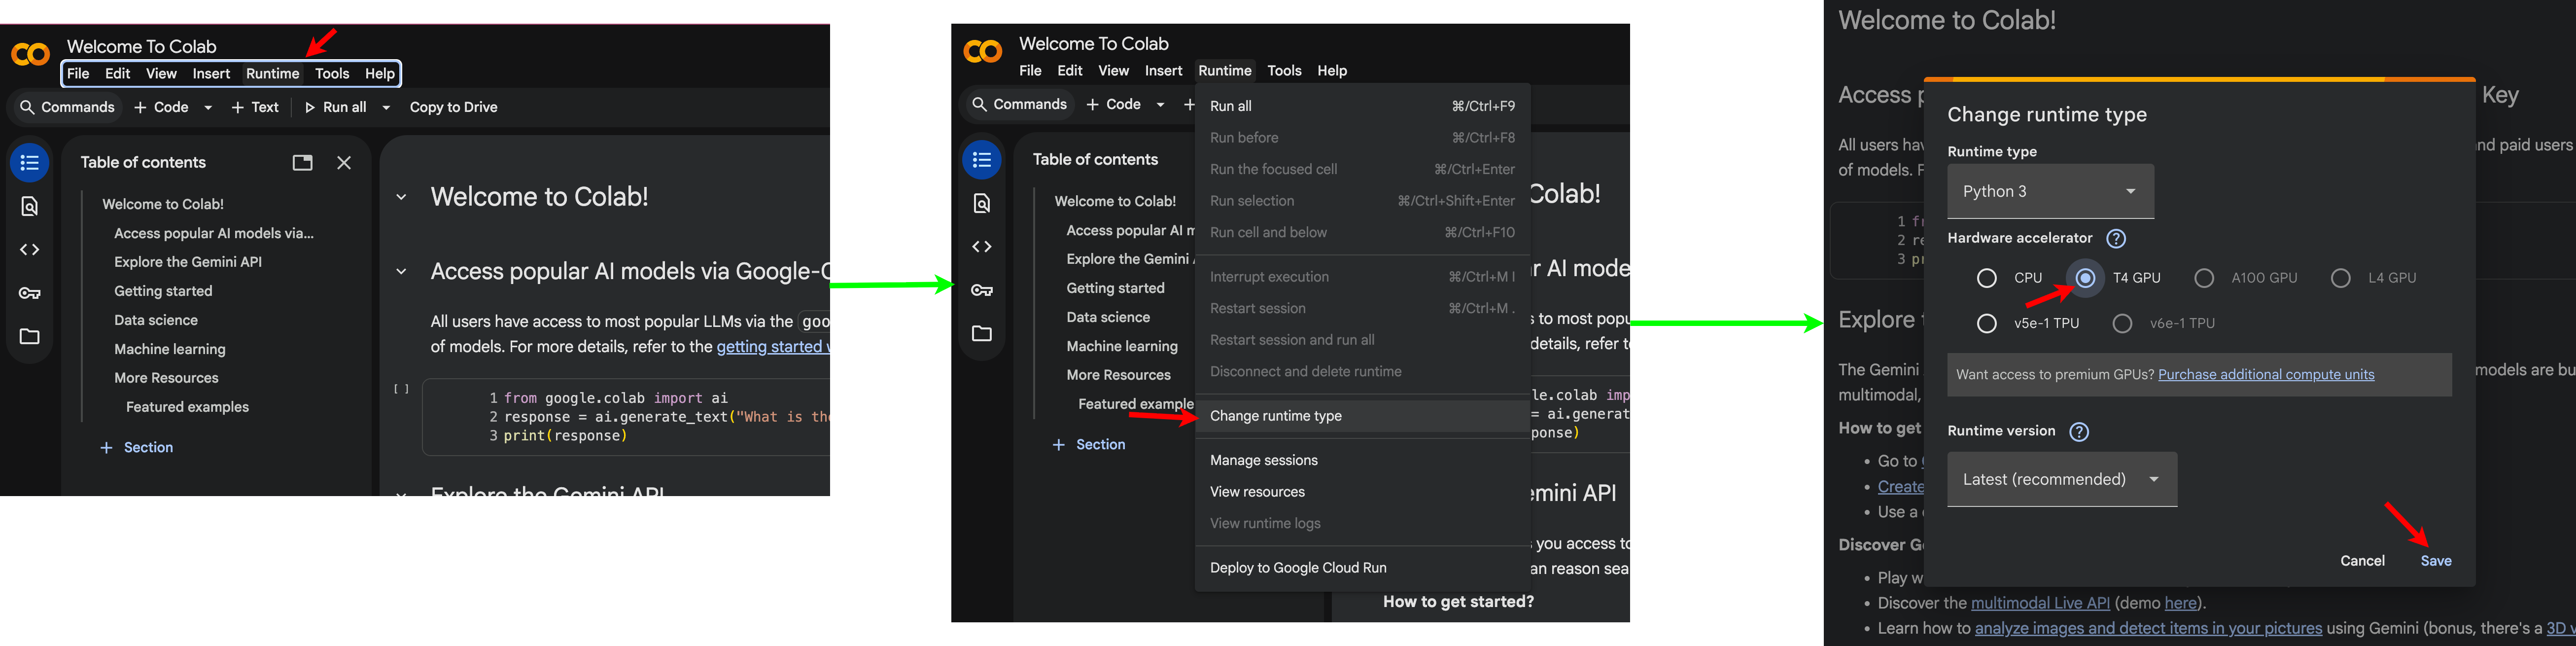

# Setup

This notebook is standalone: everything it needs is installed by the cells below. We will meet each of these libraries when we need it.

* [MuJoCo](https://mujoco.readthedocs.io/): the physics simulator,
* [mediapy](https://github.com/google/mediapy): displaying images and videos in the notebook (requires ffmpeg),
* [ur-analytic-ik](https://github.com/airo-ugent/ur-analytic-ik): an analytical inverse kinematics solver for Universal Robots arms.

In [ ]:
!pip install -q mujoco mediapy ur-analytic-ik
!command -v ffmpeg >/dev/null || (apt-get -qq update && apt-get -qq install -y ffmpeg)

MuJoCo renders images with OpenGL. The collapsed cell below tells it to render off-screen (with the GPU if there is one). Run it, but there is no need to read it.

In [ ]:
#@title Helper: off-screen rendering setup { display-mode: "form" }
import os
import platform
import subprocess

if platform.system() != "Darwin":  # on macOS, MuJoCo uses the native OpenGL implementation
    try:
        has_gpu = subprocess.run("nvidia-smi", capture_output=True).returncode == 0
    except FileNotFoundError:
        has_gpu = False
    if has_gpu:
        # Colab GPU runtimes lack the config file that lets OpenGL find the NVIDIA EGL driver. Create it.
        NVIDIA_ICD_CONFIG_PATH = "/usr/share/glvnd/egl_vendor.d/10_nvidia.json"
        if not os.path.exists(NVIDIA_ICD_CONFIG_PATH):
            os.makedirs(os.path.dirname(NVIDIA_ICD_CONFIG_PATH), exist_ok=True)
            with open(NVIDIA_ICD_CONFIG_PATH, "w") as f:
                f.write('{"file_format_version": "1.0.0", "ICD": {"library_path": "libEGL_nvidia.so.0"}}')
    os.environ["MUJOCO_GL"] = "egl"  # off-screen rendering (software-rendered if there is no GPU)

Finally, we need a model of our robot. We will use the [UR5e](https://www.universal-robots.com/products/ur5e/), a popular 6-joint industrial arm, taken from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie), a curated collection of robot models. The repository is large, so we download only the folder we need.

In [ ]:
import os

if not os.path.exists("mujoco_menagerie/universal_robots_ur5e"):
    !git clone -q --depth 1 --filter=blob:none --sparse https://github.com/google-deepmind/mujoco_menagerie
    !cd mujoco_menagerie && git sparse-checkout set universal_robots_ur5e

UR5E_XML = "mujoco_menagerie/universal_robots_ur5e/ur5e.xml"
print(open(UR5E_XML).read()[:1200], "...")

In [ ]:
import mediapy as media
import mujoco
import numpy as np

np.set_printoptions(precision=3, suppress=True)  # print numbers with 3 decimals

# The N-Table Blocks World, for real(istic)

While it would have been great to work with an actual robot in a real-world setting, we will have to make do with a simulated one. [MuJoCo](https://mujoco.org/) (short for "Multi-Joint dynamics with Contact") is a physics engine widely used in robotics research. It simulates articulated bodies with masses, inertias and joints, as well as the contacts between them, so blocks rest on tables and get pushed around when the robot bumps into them.

A MuJoCo scene is described in an XML format called [MJCF](https://mujoco.readthedocs.io/en/stable/XMLreference.html). Here is our NTBW: three tables and five blocks, named after the objects of the PDDL problem from the previous tutorial (`b1`, ..., `b5` and `t1`, `t2`, `t3`), in the same initial state: yellow `b1` on `t1` with blue `b2` on top of it, yellow `b3` on `t2`, and green `b4` and red `b5` on `t3`. The robot will stand on the pedestal in the middle.

In [ ]:
SCENE_XML = """
<mujoco model="ntbw">
  <option integrator="implicitfast"/>

  <visual>
    <headlight diffuse="0.6 0.6 0.6" ambient="0.3 0.3 0.3" specular="0 0 0"/>
    <rgba haze="0.15 0.25 0.35 1"/>
  </visual>

  <asset>
    <texture type="skybox" builtin="gradient" rgb1="0.3 0.5 0.7" rgb2="0 0 0" width="512" height="3072"/>
    <texture type="2d" name="groundplane" builtin="checker" mark="edge" rgb1="0.2 0.3 0.4" rgb2="0.1 0.2 0.3"
             markrgb="0.8 0.8 0.8" width="300" height="300"/>
    <material name="groundplane" texture="groundplane" texuniform="true" texrepeat="5 5" reflectance="0.2"/>
    <material name="table" rgba="0.75 0.75 0.75 1"/>
    <material name="pedestal" rgba="0.2 0.2 0.2 1"/>
  </asset>

  <!-- MuJoCo box sizes are HALF sizes: blocks are 8cm x 8cm x 4cm, table tops are 60cm x 60cm x 2cm -->
  <default>
    <default class="block">
      <geom type="box" size="0.04 0.04 0.02" mass="0.1"/>
    </default>
    <default class="table_top">
      <geom type="box" size="0.3 0.3 0.01" pos="0 0 0.71" material="table"/>
    </default>
    <default class="table_leg">
      <geom type="cylinder" size="0.02 0.35" material="table"/>
    </default>
  </default>

  <worldbody>
    <light pos="0 0 2.5" dir="0 0 -1" directional="true"/>
    <geom name="floor" size="0 0 0.05" type="plane" material="groundplane"/>

    <!-- the robot will be attached to this site, at the top of the pedestal (turned to face table t2) -->
    <body name="mount" pos="0 0 0.75" euler="0 0 180">
      <geom name="pedestal" type="cylinder" size="0.12 0.375" pos="0 0 -0.375" material="pedestal"/>
      <site name="mount_site"/>
    </body>

    <!-- three tables, named as in the PDDL problem of tutorial 1.1 -->
    <body name="t1" pos="0 -0.65 0">
      <geom name="t1_top" class="table_top"/>
      <geom class="table_leg" pos="0.26 -0.26 0.35"/>
      <geom class="table_leg" pos="0.26 0.26 0.35"/>
      <geom class="table_leg" pos="-0.26 -0.26 0.35"/>
      <geom class="table_leg" pos="-0.26 0.26 0.35"/>
    </body>
    <body name="t2" pos="0.65 0 0">
      <geom name="t2_top" class="table_top"/>
      <geom class="table_leg" pos="0.26 -0.26 0.35"/>
      <geom class="table_leg" pos="0.26 0.26 0.35"/>
      <geom class="table_leg" pos="-0.26 -0.26 0.35"/>
      <geom class="table_leg" pos="-0.26 0.26 0.35"/>
    </body>
    <body name="t3" pos="0 0.65 0">
      <geom name="t3_top" class="table_top"/>
      <geom class="table_leg" pos="0.26 -0.26 0.35"/>
      <geom class="table_leg" pos="0.26 0.26 0.35"/>
      <geom class="table_leg" pos="-0.26 -0.26 0.35"/>
      <geom class="table_leg" pos="-0.26 0.26 0.35"/>
    </body>

    <!-- five blocks, named as in the PDDL problem of tutorial 1.1. A freejoint lets a body move freely. -->
    <body name="b1" pos="0.05 -0.6 0.74"><freejoint name="b1_joint"/><geom name="b1" class="block" rgba="1 0.9 0 1"/></body>
    <body name="b2" pos="0.05 -0.6 0.78"><freejoint name="b2_joint"/><geom name="b2" class="block" rgba="0.1 0.3 1 1"/></body>
    <body name="b3" pos="0.6 0.1 0.74"><freejoint name="b3_joint"/><geom name="b3" class="block" rgba="1 0.9 0 1"/></body>
    <body name="b4" pos="-0.1 0.55 0.74"><freejoint name="b4_joint"/><geom name="b4" class="block" rgba="0.1 0.8 0.2 1"/></body>
    <body name="b5" pos="0.15 0.7 0.74"><freejoint name="b5_joint"/><geom name="b5" class="block" rgba="1 0.1 0.1 1"/></body>

    <!-- cameras to watch the scene from -->
    <camera name="overview" mode="targetbody" target="mount" pos="1.9 -1.9 1.9"/>
    <camera name="front" mode="targetbody" target="mount" pos="2.4 0 1.5"/>
    <camera name="side" mode="targetbody" target="mount" pos="0 -2.4 1.5"/>
    <camera name="top" pos="0 0 3.0" xyaxes="0 1 0 -1 0 0"/>
  </worldbody>
</mujoco>
"""

BLOCKS = ["b1", "b2", "b3", "b4", "b5"]
TABLES = ["t1", "t2", "t3"]
BLOCK_HALF_HEIGHT = 0.02

The robot comes in its own MJCF file. MuJoCo's `MjSpec` API lets us load several files and *attach* one to another. We attach the UR5e to the `mount_site` at the top of the pedestal, and then attach a simple **suction gripper** to the robot's flange (its `attachment_site`). All the elements of the robot get the prefix `robot_` and those of the gripper get `tool_`.

Real suction cups work by creating a vacuum. Instead of simulating that, when we "activate" the suction, we tell MuJoCo to keep the block welded to the cup with a *weld constraint* (one per block, all inactive for now). This is a common trick in simulation, and it keeps us focused on the topic of this tutorial. The site `tcp` at the tip of the cup is the **tool center point**: the point we will want to position when we pick things up.

In [ ]:
TOOL_XML = """
<mujoco model="suction_gripper">
  <worldbody>
    <body name="suction_cup">
      <geom name="suction_cup" type="cylinder" size="0.02 0.03" pos="0 0 0.03" rgba="0.3 0.3 0.3 1" mass="0.05"/>
      <site name="tcp" pos="0 0 0.06" size="0.005" rgba="1 0 0 1"/>
    </body>
  </worldbody>
</mujoco>
"""


def build_model():
    scene = mujoco.MjSpec.from_string(SCENE_XML)
    robot = mujoco.MjSpec.from_file(UR5E_XML)
    tool = mujoco.MjSpec.from_string(TOOL_XML)

    scene.attach(robot, site="mount_site", prefix="robot_")
    scene.attach(tool, site="robot_attachment_site", prefix="tool_")

    # one (inactive) weld constraint per block, for our simplified suction gripper
    for block in BLOCKS:
        scene.add_equality(name=f"grasp_{block}", type=mujoco.mjtEq.mjEQ_WELD, objtype=mujoco.mjtObj.mjOBJ_BODY,
                           name1="tool_suction_cup", name2=block, active=False)

    return scene.compile()


model = build_model()  # MjModel: everything that does not change during simulation (geometry, masses, ...)
data = mujoco.MjData(model)  # MjData: everything that does (positions, velocities, contacts, ...)

print(f"{model.nbody} bodies, {model.ngeom} geoms, {model.njnt} joints, {model.nu} actuators")

The cameras we defined in the scene let us look at it. `mujoco.Renderer` renders an image of the current `data` from a chosen camera. We wrap it in a small helper.

In [ ]:
renderer = mujoco.Renderer(model, height=480, width=640)


def render(camera="overview"):
    """An RGB image of the current state of the simulation, seen from the named camera."""
    renderer.update_scene(data, camera=camera)
    return renderer.render()


mujoco.mj_forward(model, data)  # compute positions of all bodies from the (initial) joint positions
media.show_image(render())

Note the call to `mujoco.mj_forward`: MuJoCo does not compute anything (not even where the bodies are) until asked. `mj_forward` runs the *forward dynamics* pipeline (kinematics, collision detection, contact forces) for the current state without advancing time. We will use this a lot.

## The state of the world

In the previous tutorial, a state was a set of facts like `(on b2 b1)`. Here, the state of the simulation is a vector of numbers, `data.qpos`, holding the position of every *joint* in the scene. The robot has 6 joints, each a single angle. Each block has a *free joint*, which takes 7 numbers: its position (3) and its orientation as a unit quaternion (4).

In [ ]:
print("qpos has", model.nq, "numbers")
for i in range(model.njnt):
    joint = model.joint(i)
    print(f"  {joint.name:26s} {joint.qposadr[0]:2d}..{joint.qposadr[0] + (7 if joint.type == mujoco.mjtJoint.mjJNT_FREE else 1) - 1:2d}")

Everything about the robot is identified by name, so let's collect the indices we need: where the robot's joint positions live in `qpos`, its joint velocities in `qvel`, and which entries of `ctrl` (the control input) belong to its actuators. We do this by name so that the code does not depend on the order in which things happen to be stored.

In [ ]:
ROBOT_JOINTS = ["shoulder_pan_joint", "shoulder_lift_joint", "elbow_joint", "wrist_1_joint", "wrist_2_joint", "wrist_3_joint"]
ROBOT_ACTUATORS = ["shoulder_pan", "shoulder_lift", "elbow", "wrist_1", "wrist_2", "wrist_3"]

qpos_idx = np.array([model.joint("robot_" + name).qposadr[0] for name in ROBOT_JOINTS])
qvel_idx = np.array([model.joint("robot_" + name).dofadr[0] for name in ROBOT_JOINTS])
ctrl_idx = np.array([model.actuator("robot_" + name).id for name in ROBOT_ACTUATORS])


def get_configuration():
    """The robot's joint angles (radians)."""
    return data.qpos[qpos_idx].copy()


def get_joint_velocities():
    return data.qvel[qvel_idx].copy()


def get_block_positions():
    """The position of the center of every block, in world coordinates."""
    return {block: data.body(block).xpos.copy() for block in BLOCKS}


print("robot configuration:", get_configuration())
print("block positions:")
for block, position in get_block_positions().items():
    print(f"  {block}: {position}")

❓ **Where in this state is the fact `(on b2 b1)`?** It is not stored anywhere. It is implied by the numbers (`b2` is 4 cm above `b1`, at the same x and y), and to use a task planner we would have to compute it from them. We will do that in the state estimation tutorial.

Note also that the block positions and the robot configuration are copies: MuJoCo updates its arrays in place, so a reference to `data.qpos` would silently change as the simulation runs.

## Workspace and configuration space

Two concepts are essential for talking about robot motion.

The **workspace** is the physical space in which the robot operates: the volume that the arm, and in particular its end effector, can reach. Our tasks are naturally specified here: "put the suction cup 10 cm above block `b3`".

The **configuration space** (C-space) is the set of all possible *configurations* of the robot, where a configuration is a complete specification of the position of every part of the robot. For an arm with rigid links, the joint angles are such a specification: fix them and you know where every link is. The dimension of the C-space is the number of **degrees of freedom (DOF)** of the robot. The robot is *controlled* here: we tell each joint where to go.

The image below, taken from [Modern Robotics](https://hades.mech.northwestern.edu/images/7/7f/MR.pdf) (Lynch and Park), shows configurations of three different objects.

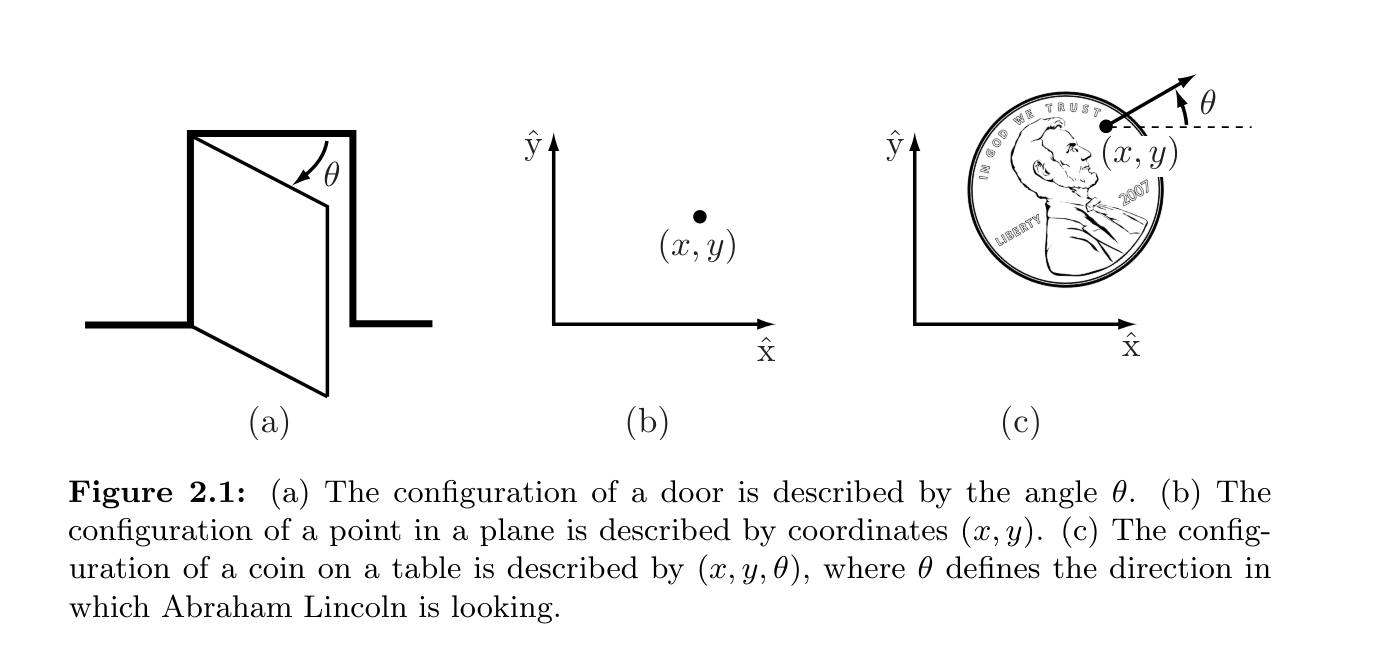

The UR5e has 6 revolute joints, so its C-space is 6-dimensional: a configuration is a vector $q = (q_1, \dots, q_6)$ of joint angles. In order, the joints are the shoulder pan, the shoulder lift, the elbow, and three wrist joints.

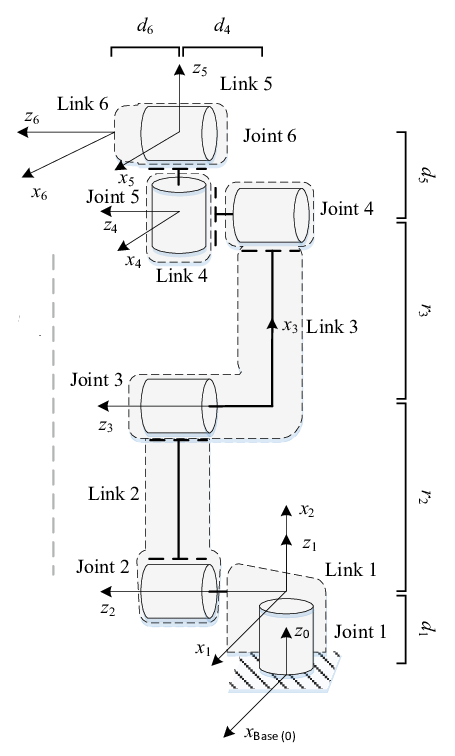

The relationship between the two spaces is not intuitive. [This online demo](https://robotics.cs.unc.edu/C-space/index.html), created by Prof. Ron Alterovitz at UNC, lets you drag a 2-joint planar arm around and see its workspace (left) and C-space (right) side by side, including how obstacles in the workspace map to forbidden regions of the C-space. Take a minute to play with it.

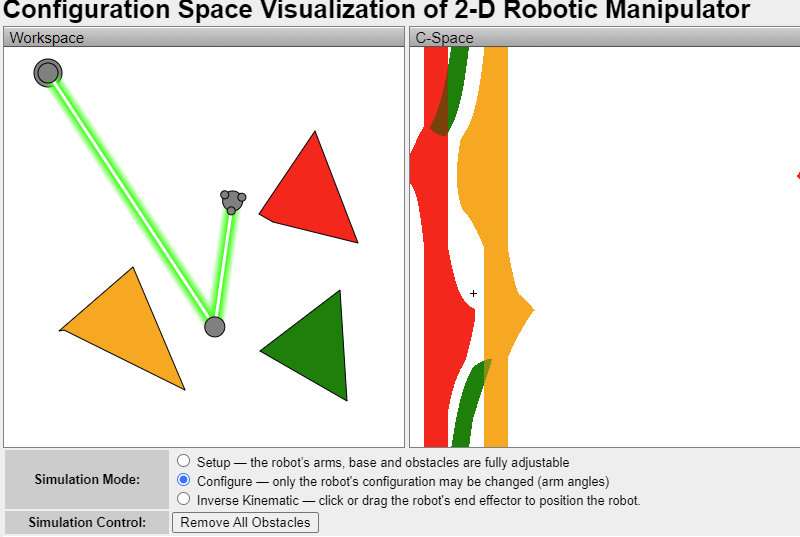

❓ **How many dimensions does the configuration space of our entire scene have?** Count the robot's joints and the blocks' free joints (a free body has 6 degrees of freedom). Why does `qpos` have more numbers than that?

# Moving the robot

In our simulation, the robot's actuators are *position servos*: the control input of each actuator is a target joint angle, and the actuator applies a torque proportional to the difference between the target and the current angle (with some damping). If we keep the same target for a while, the joint settles close to it. In other words, our **actions are target configurations**.

Note the difference from task planning, where actions were instantaneous. Here we must keep the target applied for enough simulation steps for the robot to get there, and physics decides what actually happens on the way. Where the torques come from is the topic of the control tutorial; for now we take the servos for granted.

Let's send the robot to a configuration and record a video. `mujoco.mj_step` advances the simulation by one time step (2 milliseconds here). Rendering is much slower than simulating, so we render only every few steps.

In [ ]:
def show_video(frames, fps=10):
    if len(frames) == 0:
        print("(no frames to show)")
    else:
        media.show_video(frames, fps=fps)


mujoco.mj_resetData(model, data)  # back to the initial state

target = np.array([0, -np.pi / 2, np.pi / 2, -np.pi / 2, -np.pi / 2, 0])
number_of_steps = 500

frames = []
for i in range(number_of_steps):
    data.ctrl[ctrl_idx] = target  # the action: a target configuration
    mujoco.mj_step(model, data)
    if i % 25 == 0:
        frames.append(render())

print("target:       ", target)
print("configuration:", get_configuration())
show_video(frames)

⚒ **Task 1**: Change `number_of_steps` to 50 and to 2000 and re-run the cell. How close does the robot get to the target in each case? Does it ever get there exactly?

The robot gets close to the target and stays there, but not exactly at it. Gravity pulls on the arm, and a proportional servo needs some error to produce the torque that holds it up. We will fix this in the control tutorial. For now, let's write a convenience function that keeps applying a target until the robot is close enough to it *and* has (almost) stopped moving, or gives up after a maximum number of steps.

In [ ]:
def move_to(target, tolerance=0.03, max_steps=2000, render_every=50, camera="overview"):
    """Apply the target configuration until the robot reaches it (within tolerance, radians) and stops moving.

    Returns (success, frames): whether the target was reached, and video frames of the motion.
    """
    frames = []
    for i in range(max_steps):
        data.ctrl[ctrl_idx] = target
        mujoco.mj_step(model, data)
        if i % render_every == 0:
            frames.append(render(camera))
        if np.linalg.norm(get_configuration() - target) < tolerance and np.linalg.norm(get_joint_velocities()) < 0.05:
            return True, frames
    return False, frames

The configuration we used above is a comfortable "ready" pose, with the elbow up and the suction cup pointing down. We will use it as the robot's **home** configuration, and write a `reset` that brings the world back to its initial state, with the robot at home.

In [ ]:
HOME = np.array([0, -np.pi / 2, np.pi / 2, -np.pi / 2, -np.pi / 2, 0])


def reset():
    """Reset the simulation to the initial state, with the robot at the home configuration."""
    mujoco.mj_resetData(model, data)
    data.qpos[qpos_idx] = HOME
    data.ctrl[ctrl_idx] = HOME
    data.eq_active[:] = 0  # no block is grasped
    mujoco.mj_forward(model, data)


reset()
success, frames = move_to([-np.pi / 4] * 6)
print("reached:", success)
show_video(frames)

⚒ **Task 2**: Recall that our task is to pick up and move blocks. Find, by hand, a configuration that brings the suction cup right above the yellow block `b3` on table `t2` (the one in front of the robot, along the x axis), with the cup pointing down. Aim for the `tcp` site to be about 10 cm above the top of the block. Give it 3-5 attempts, using the printed distance and the video to guide you. The cell prints the position of the tool center point and its distance from the target.

*Hints:* the joints, in order, are shoulder pan, shoulder lift, elbow, wrist 1, wrist 2, wrist 3 (see the figure above). Start from `HOME`, which already faces table `t2`, and change one joint at a time. Lowering the arm while keeping the cup pointing down involves more than one joint.

In [ ]:
above_b3 = get_block_positions()["b3"] + [0, 0, BLOCK_HALF_HEIGHT + 0.1]
print("target position for the tool center point:", above_b3)


def get_tcp_position():
    return data.site("tool_tcp").xpos.copy()


reset()
your_config = HOME.copy()  # your code here: edit the configuration
success, frames = move_to(your_config)

print("tool center point at:", get_tcp_position(), " distance to target: %.3f m" % np.linalg.norm(get_tcp_position() - above_b3))
show_video(frames)

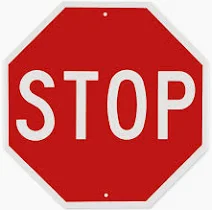

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
reset()
proposed_config = [-0.06, -1.07, 1.81, -2.31, -1.57, -1.63]
success, frames = move_to(proposed_config)

print("tool center point at:", get_tcp_position(), " distance to target: %.3f m" % np.linalg.norm(get_tcp_position() - above_b3))
media.show_image(render())

Finding joint angles by trial and error is tedious, even though the robot has only 6 joints. This is the problem that **kinematics** solves.

# Forward Kinematics

![forward and inverse kinematics](https://github.com/CLAIR-LAB-TECHNION/ICAPS-24/blob/main/assets/figures/f_inv_kinematics.png?raw=true)

**Forward kinematics (FK)** is the mapping from a configuration $q$ to the *pose* (position and orientation) of the end effector in the workspace. It is always computable and relatively simple, provided we know the geometry of the robot: where each joint sits relative to the previous one, and about which axis it rotates.

Poses are represented by $4 \times 4$ **homogeneous transformation matrices**. A transformation
$$T = \begin{bmatrix} R & t \\ 0 & 1 \end{bmatrix}$$
holds a rotation matrix $R$ ($3 \times 3$) and a translation vector $t$, and maps points expressed in one frame to their coordinates in another: $p' = R p + t$. Composing two transformations is a matrix product. Forward kinematics is the product of the transformations along the arm: from the base to the first joint, the rotation of the first joint about its axis, from the first joint to the second, and so on down to the end effector:
$$T_{\text{end effector}}(q) = T_{\text{base}} \; T_1(q_1) \; T_2(q_2) \cdots T_6(q_6) \; T_{\text{tool}}.$$

MuJoCo does this for us, since it needs these poses to simulate anything. After `mj_forward`, the pose of every body, geom and site is available. We do not even need to simulate physics. We can *set* the configuration and ask for the resulting pose. Let's define a function that teleports the robot to a configuration, and one that reads the pose of the tool center point.

In [ ]:
def set_configuration(q):
    """Teleport the robot to configuration q. This only updates kinematics, no physics is simulated."""
    data.qpos[qpos_idx] = q
    mujoco.mj_forward(model, data)


def get_tcp_pose():
    """Position (3,) and orientation (3x3 rotation matrix) of the tool center point in the world frame."""
    site = data.site("tool_tcp")
    return site.xpos.copy(), site.xmat.reshape(3, 3).copy()


reset()
set_configuration(proposed_config)
position, rotation = get_tcp_pose()
print("tcp position:\n", position)
print("tcp orientation:\n", rotation)
media.show_image(render("front"))

The columns of the rotation matrix are the axes of the tool frame expressed in world coordinates. The third column, the tool's z axis, is $(0, 0, -1)$, so the cup points straight down, as required.

To see that forward kinematics really is a chain of matrix products, let's compute it ourselves from the numbers stored in the model. For each body on the chain from the world to the tool, the model stores the pose of the body relative to its parent (`body.pos`, `body.quat`) and, if the body has a joint, the axis of rotation (`joint.axis`). Note that `mount` and `robot_base` have no joint, so they are fixed transformations.

In [ ]:
def transformation(position, quaternion):
    """The 4x4 homogeneous transformation of a pose given as position and unit quaternion (w, x, y, z)."""
    rotation = np.zeros(9)
    mujoco.mju_quat2Mat(rotation, quaternion)
    T = np.eye(4)
    T[:3, :3] = rotation.reshape(3, 3)
    T[:3, 3] = position
    return T


def rotation_about(axis, angle):
    """The 4x4 transformation of a rotation by angle (radians) about the given axis."""
    quaternion = np.zeros(4)
    mujoco.mju_axisAngle2Quat(quaternion, axis, angle)
    return transformation(np.zeros(3), quaternion)


def forward_kinematics_by_hand(q):
    """The pose of the tool center point as a 4x4 transformation, computed as a chain of matrix products."""
    # the chain of bodies from the world to the body holding the tcp site
    chain = []
    body_id = model.site("tool_tcp").bodyid[0]
    while body_id != 0:  # body 0 is the world
        chain.append(body_id)
        body_id = model.body(body_id).parentid[0]
    chain.reverse()

    T = np.eye(4)
    for body_id in chain:
        body = model.body(body_id)
        T = T @ transformation(body.pos, body.quat)  # fixed transformation from the parent body
        if body.jntnum[0] > 0:  # the body moves relative to its parent: rotate about the joint axis
            joint = model.joint(body.jntadr[0])
            joint_index = ROBOT_JOINTS.index(joint.name.removeprefix("robot_"))
            T = T @ rotation_about(joint.axis, q[joint_index])
    site = model.site("tool_tcp")
    return T @ transformation(site.pos, site.quat)


print("bodies on the chain:")
body_id = model.site("tool_tcp").bodyid[0]
while body_id != 0:
    print("  ", model.body(body_id).name)
    body_id = model.body(body_id).parentid[0]

q = np.random.uniform(-np.pi, np.pi, 6)  # a random configuration
set_configuration(q)
position, rotation = get_tcp_pose()
T = forward_kinematics_by_hand(q)
print("\nby hand:", T[:3, 3], "\nmujoco: ", position, "\nlargest difference:", np.abs(T[:3, 3] - position).max())

❓ **Which joint can we change without moving the tool center point at all?** Think about the axes in the figure of the UR5 above, then check your answer with `forward_kinematics_by_hand`.

# Inverse Kinematics

**Inverse kinematics (IK)** goes the other way: given a desired pose of the end effector, find a configuration $q$ that achieves it. This is what we needed in Task 2. It is harder than forward kinematics for several reasons:

* the mapping is nonlinear (products of sines and cosines of the joint angles), so there is no general formula to invert it,
* there may be **no solution** (the pose is out of reach),
* there may be **several solutions** (reach the same point with the elbow up or down), or infinitely many (for arms with more than 6 joints).

There are two families of approaches. **Numerical** IK treats the problem as root finding or optimization and iterates from an initial guess. It works for any robot, but it finds one solution (the one "near" the initial guess) and may fail to converge. **Analytical** IK derives closed-form expressions for the joint angles from the specific geometry of a robot. It returns all solutions and is very fast, but it exists only for certain robot geometries, and must be derived for each robot. We will try both.

## Numerical IK with the Jacobian

Consider the forward kinematics as a function $x = f(q)$ from the 6 joint angles to the 6 numbers describing the end-effector pose (3 for position and 3 for orientation). For a small change $\Delta q$ of the configuration, the pose changes approximately linearly:
$$\Delta x \approx J(q) \, \Delta q,$$
where $J(q)$ is the $6 \times 6$ **Jacobian** matrix of $f$ at $q$. The Jacobian tells us how each joint moves the end effector, and MuJoCo can compute it for us (`mj_jacSite`).

This suggests an iterative algorithm (a variant of Newton's method). Starting from a guess $q$:

1. compute the current pose $f(q)$ and the error $e = x_{\text{target}} - f(q)$,
2. find the joint change that would cancel the error, $\Delta q = J^{-1} e$,
3. update $q \leftarrow q + \Delta q$ and repeat until the error is small.

Inverting $J$ directly is a bad idea, because near *singular* configurations (e.g., a fully stretched arm) $J$ is nearly singular and $\Delta q$ becomes very large. The standard fix is **damped least squares**: $\Delta q = J^T (J J^T + \lambda^2 I)^{-1} e$, which behaves like the inverse when $J$ is well conditioned and takes small, safe steps when it is not.

The error has two parts. The position part is simply the difference of the positions, and the orientation part is the *rotation vector* (axis times angle) of the rotation that takes the current orientation to the target one. The helpers below take care of that.

In [ ]:
def orientation_error(target_rotation, current_rotation):
    """The rotation vector (axis * angle, in the world frame) that rotates current_rotation onto target_rotation."""
    relative = target_rotation @ current_rotation.T
    quaternion = np.zeros(4)
    mujoco.mju_mat2Quat(quaternion, relative.flatten())
    rotation_vector = np.zeros(3)
    mujoco.mju_quat2Vel(rotation_vector, quaternion, 1.0)
    return rotation_vector


def pose_error(target_position, target_rotation):
    """The 6-dimensional error between the target pose and the current pose of the tool center point."""
    position, rotation = get_tcp_pose()
    return np.concatenate([target_position - position, orientation_error(target_rotation, rotation)])


def tcp_jacobian():
    """The 6x6 Jacobian of the tool center point pose with respect to the robot's joint angles, at the current configuration."""
    jac_position = np.zeros((3, model.nv))
    jac_rotation = np.zeros((3, model.nv))
    mujoco.mj_jacSite(model, data, jac_position, jac_rotation, model.site("tool_tcp").id)
    return np.vstack([jac_position, jac_rotation])[:, qvel_idx]  # keep only the robot's joints


def wrap_angles(q):
    """Wrap angles to [-pi, pi]. Joint angles are periodic, and this keeps them inside the robot's joint limits."""
    return (q + np.pi) % (2 * np.pi) - np.pi

⚒ **Task 3**: Complete the update step of `numerical_ik` below with damped least squares.

*Hints:* `np.linalg.solve(A, b)` solves $A y = b$, `J.T` transposes, and `np.eye(6)` is the identity.

In [ ]:
def numerical_ik(target_position, target_rotation, initial_guess, max_iterations=100, tolerance=1e-4, damping=1e-3):
    """Iteratively find a configuration that brings the tool center point to the target pose.

    Returns (q, converged, errors): the final configuration, whether the error dropped below tolerance,
    and the list of error norms of all iterations.
    """
    q = np.array(initial_guess, dtype=float)
    errors = []
    converged = False
    for iteration in range(max_iterations):
        set_configuration(q)
        error = pose_error(target_position, target_rotation)
        errors.append(np.linalg.norm(error))
        if errors[-1] < tolerance:
            converged = True
            break

        J = tcp_jacobian()
        delta_q = np.zeros(6)  # your code here: damped least squares step

        q = wrap_angles(q + delta_q)
    return q, converged, errors

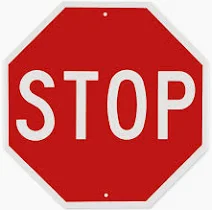

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
def numerical_ik(target_position, target_rotation, initial_guess, max_iterations=100, tolerance=1e-4, damping=1e-3):
    q = np.array(initial_guess, dtype=float)
    errors = []
    converged = False
    for iteration in range(max_iterations):
        set_configuration(q)
        error = pose_error(target_position, target_rotation)
        errors.append(np.linalg.norm(error))
        if errors[-1] < tolerance:
            converged = True
            break

        J = tcp_jacobian()
        delta_q = J.T @ np.linalg.solve(J @ J.T + damping**2 * np.eye(6), error)

        q = wrap_angles(q + delta_q)
    return q, converged, errors

Let's solve Task 2 properly: bring the cup 10 cm above `b3`, pointing down. A rotation matrix whose third column is $(0, 0, -1)$ points the tool's z axis down; the one below also keeps the tool's x axis aligned with the world's x axis.

In [ ]:
import matplotlib.pyplot as plt

FACING_DOWN = np.array([[1, 0, 0],
                        [0, -1, 0],
                        [0, 0, -1]])

reset()
q, converged, errors = numerical_ik(above_b3, FACING_DOWN, initial_guess=HOME)
print("converged:", converged, "after", len(errors), "iterations")
print("configuration:", q)

plt.figure(figsize=(5, 3))
plt.semilogy(errors)
plt.xlabel("iteration")
plt.ylabel("pose error")
plt.title("Convergence of numerical IK")
plt.show()

reset()
success, frames = move_to(q)
print("tool center point at:", get_tcp_position(), " distance to target: %.3f m" % np.linalg.norm(get_tcp_position() - above_b3))
show_video(frames)

A few things to note:

* The solver converged in a handful of iterations, but the configuration it found is *not* the one we proposed for Task 2, and both are correct. Numerical IK finds *a* solution, typically the one closest to the initial guess.
* The distance to the target after `move_to` is larger than the IK error. The IK solution is exact up to the solver's tolerance, but the servos stop slightly short of it (remember Task 1).

⚒ **Task 3.1**: Run `numerical_ik` for the same target from several random initial guesses (`np.random.uniform(-np.pi, np.pi, 6)`). How many different solutions do you find? Then try a target that is clearly out of reach, e.g. `[1.5, 0, 0.9]`. What happens to the error?

In [ ]:
# your code here

❓ **Would you trust this solver inside a robot's control loop, where IK may be called thousands of times per second?** What could go wrong?

## Analytical IK

For the UR5e (and most 6-joint industrial arms) the inverse kinematics can be solved in closed form. The geometry of a UR arm gives up to **8 solutions** for a reachable pose: the shoulder can be on either side of the target (*shoulder left/right*), the elbow can be *up or down*, and the wrist can be *flipped or not*. Deriving the formulas is a classic exercise in robotics courses; we will use the [ur-analytic-ik](https://github.com/airo-ugent/ur-analytic-ik) library, which implements them for the whole UR family.

The library knows only the robot, not our scene. It expects the pose of the robot's **flange** (the mounting plate at the end of the arm, our `attachment_site`) relative to the robot's **base**, and returns joint angles. We have a target for the **tool center point** in the **world** frame. To bridge the two, we need to convert between **reference frames**. This comes up whenever a tool made for one robot is used in a different scene.

### Reference frames

A reference frame is defined by the position of its origin and the orientation of its axes, relative to some other frame (ultimately, the world frame). MuJoCo gives us both for every body: `data.body(name).xpos` and `data.body(name).xmat`. Together they form a transformation $T_A = \begin{bmatrix} R_A & t_A \\ 0 & 1 \end{bmatrix}$ that maps coordinates in frame $A$ to world coordinates: $p_{\text{world}} = R_A p_A + t_A$.

To go the other way, from world coordinates to frame $A$, we invert:
$$p_A = R_A^T (p_{\text{world}} - t_A), \qquad T_A^{-1} = \begin{bmatrix} R_A^T & -R_A^T t_A \\ 0 & 1 \end{bmatrix}.$$

And to express an entire pose $T_B$ (given in world coordinates) relative to frame $A$:
$$T_A^{-1} T_B = \begin{bmatrix} R_A^T R_B & R_A^T (t_B - t_A) \\ 0 & 1 \end{bmatrix}.$$

The robot's base frame is the `mount` body in our scene (that is where we attached the robot).

⚒ **Task 4**: Implement `world_to_base`, which takes a pose (position and rotation matrix) in world coordinates and returns the same pose relative to the robot's base frame.

To check your implementation, the cell compares the pose of the flange, read from MuJoCo and transformed to the base frame with your function, with the pose computed by the library's own forward kinematics, `ur5e.forward_kinematics(*q)`, which is expressed in the base frame. They should agree to about a millimeter (the library uses the nominal dimensions of the UR5e, the simulated model differs slightly).

In [ ]:
from ur_analytic_ik import ur5e


def world_to_base(position, rotation):
    """Transform a pose from world coordinates to the robot's base frame."""
    base = data.body("mount")
    base_position, base_rotation = base.xpos, base.xmat.reshape(3, 3)

    position_in_base = position  # your code here
    rotation_in_base = rotation  # your code here

    return position_in_base, rotation_in_base


def get_flange_pose():
    site = data.site("robot_attachment_site")
    return site.xpos.copy(), site.xmat.reshape(3, 3).copy()


q = np.random.uniform(-np.pi, np.pi, 6)
set_configuration(q)
position, rotation = world_to_base(*get_flange_pose())
T_library = ur5e.forward_kinematics(*q)

print("flange position in base frame, from MuJoCo + world_to_base:", position)
print("flange position in base frame, from the library's FK:      ", T_library[:3, 3])
print("largest difference in rotation:", np.abs(rotation - T_library[:3, :3]).max())

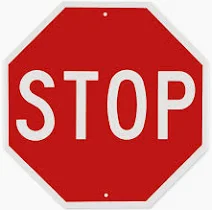

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
def world_to_base(position, rotation):
    base = data.body("mount")
    base_position, base_rotation = base.xpos, base.xmat.reshape(3, 3)

    position_in_base = base_rotation.T @ (position - base_position)
    rotation_in_base = base_rotation.T @ rotation

    return position_in_base, rotation_in_base


q = np.random.uniform(-np.pi, np.pi, 6)
set_configuration(q)
position, rotation = world_to_base(*get_flange_pose())
T_library = ur5e.forward_kinematics(*q)

print("flange position in base frame, from MuJoCo + world_to_base:", position)
print("flange position in base frame, from the library's FK:      ", T_library[:3, 3])
print("largest difference in rotation:", np.abs(rotation - T_library[:3, :3]).max())

The second conversion concerns the tool. The tool center point is 6 cm from the flange along the tool's z axis, i.e. $T_{\text{tcp}} = T_{\text{flange}} \, T_{\text{tool}}$ with a fixed $T_{\text{tool}}$. The library accepts this offset directly (`inverse_kinematics_with_tcp`). We can now write our analytical IK function: transform the target to the base frame, pack it into a $4 \times 4$ matrix, and ask for all solutions.

In [ ]:
T_TOOL = transformation(model.site("tool_tcp").pos, model.site("tool_tcp").quat)  # the tcp site relative to the flange


def analytical_ik(target_position, target_rotation):
    """All configurations that bring the tool center point to the target pose (world frame). Empty if unreachable."""
    position, rotation = world_to_base(target_position, target_rotation)
    T_flange = np.eye(4)
    T_flange[:3, :3] = rotation
    T_flange[:3, 3] = position
    return ur5e.inverse_kinematics_with_tcp(T_flange, T_TOOL)


reset()
solutions = analytical_ik(above_b3, FACING_DOWN)
print(len(solutions), "solutions:")
for solution in solutions:
    set_configuration(solution)
    print("  ", solution, " tcp error: %.1f mm" % (1000 * np.linalg.norm(get_tcp_position() - above_b3)))

The library returns eight solutions, all within a millimeter of the target. Use the slider below to look at each of them (and pick a camera).

In [ ]:
from ipywidgets import interact

CAMERAS = ["overview", "front", "side", "top"]


@interact(solution=(0, len(solutions) - 1), camera=CAMERAS)
def show_solution(solution=0, camera="overview"):
    set_configuration(solutions[solution])
    media.show_image(render(camera))

❓ **Which of these would you pick, and why?** The solutions differ in how "natural" they look, in how far they are from the current configuration (so, how much the robot must move), in how close the elbow gets to the table, and some may collide with the environment.

We can check the last criterion directly. After `mj_forward`, `data.contact` lists all pairs of geoms that are in contact (or penetrating). The function below teleports the robot to a configuration and reports whether any part of the robot or its tool touches anything (including a block it is not supposed to touch). Note that this is a *kinematic* check. Nothing is simulated; we only ask MuJoCo whether the geometry overlaps.

When measuring "how far" a solution is, we need to remember that angles are periodic. The solver returns angles in $[-\pi, \pi]$, so a solution with the shoulder pan at $3.1$ rad looks $6.2$ rad away from a robot whose pan is at $-3.1$ rad, while in fact they are $0.08$ rad apart. Sending the robot to $3.1$ would make it spin almost a full turn. `nearest_equivalent` replaces each angle by the equivalent one (a multiple of $2\pi$ away) nearest to the current configuration, as long as it stays within the joint limits.

In [ ]:
def in_collision(q):
    """Whether the robot (or its tool) is in contact with anything when placed at configuration q.

    The robot is teleported to q for the check and then put back where it was.
    """
    current = get_configuration()
    set_configuration(q)
    held = [block for block in BLOCKS if data.eq_active[model.equality(f"grasp_{block}").id]]  # a grasped block touches the cup by design
    collision = False
    for i in range(data.ncon):
        contact = data.contact[i]
        geom1, geom2 = model.geom(contact.geom1).name, model.geom(contact.geom2).name
        if geom1 in held or geom2 in held:
            continue
        if geom1.startswith(("robot_", "tool_")) or geom2.startswith(("robot_", "tool_")):
            collision = True
            break
    set_configuration(current)
    return collision


JOINT_RANGES = np.array([model.joint("robot_" + name).range for name in ROBOT_JOINTS])


def nearest_equivalent(q, reference):
    """Shift each angle of q by a multiple of 2*pi to the equivalent angle nearest to reference, within the joint limits."""
    shifted = reference + wrap_angles(q - reference)
    within_limits = (shifted >= JOINT_RANGES[:, 0]) & (shifted <= JOINT_RANGES[:, 1])
    return np.where(within_limits, shifted, q)


def choose_solution(solutions, reference):
    """The collision-free solution closest to the reference configuration, or None if there is none."""
    free = [nearest_equivalent(q, reference) for q in solutions if not in_collision(q)]
    if not free:
        return None
    return min(free, key=lambda q: np.linalg.norm(q - reference))


print("in collision:", [in_collision(q) for q in solutions])
q_above_b3 = choose_solution(solutions, HOME)
print("chosen:", q_above_b3)

None of the eight solutions collides with anything here, since the tables are far from the robot's base. Now let's compare the two solvers on speed.

In [ ]:
import time

reset()
start = time.time()
for _ in range(100):
    numerical_ik(above_b3, FACING_DOWN, initial_guess=HOME)
print("numerical IK:  %.2f ms per call, 1 solution" % (10 * (time.time() - start)))

start = time.time()
for _ in range(100):
    analytical_ik(above_b3, FACING_DOWN)
print("analytical IK: %.3f ms per call, %d solutions" % (10 * (time.time() - start), len(solutions)))

The analytical solver is an order of magnitude faster, returns every solution, and never "fails to converge". When an analytical solver is available, it is usually preferred, and we will rely on it for the rest of the workshop. The numerical solver is still the more general one. It works for any kinematic chain (humanoids, 7-joint arms, several arms at once) and it is easy to add constraints to it (joint limits, preferred postures). This is how most robots without a closed-form solution do IK.

# Pick-up in the real(istic) world

We can now ground the task planning action `pick-up(b5, t3)` in our robotic setting. Picking up a block with a suction cup means:

1. moving the cup to a **pre-grasp** pose above the block (so that we approach it from above),
2. descending until the cup (almost) touches the top of the block,
3. activating the suction,
4. lifting the block.

Each of these is a target pose for the tool center point, which IK turns into a configuration, which `move_to` executes. Among the IK solutions, we always pick the collision-free one closest to the current configuration, so that every step moves the robot as little as possible.

The helpers below compute the pre-grasp and grasp poses of a block from its current position, and implement the suction with the weld constraints we prepared when building the model.

In [ ]:
def pose_above(block, height=0.1):
    """The tcp pose `height` meters above the top of the block, facing down."""
    top = data.body(block).xpos + [0, 0, BLOCK_HALF_HEIGHT]
    return top + [0, 0, height], FACING_DOWN


def grasp(max_distance=0.03):
    """Activate the suction: weld the block whose top is within max_distance of the tcp to the cup. Returns the block or None."""
    tcp = get_tcp_position()
    cup = data.body("tool_suction_cup")
    for block in BLOCKS:
        body = data.body(block)
        if np.linalg.norm(body.xpos + [0, 0, BLOCK_HALF_HEIGHT] - tcp) < max_distance:
            # the weld keeps the block at its current pose relative to the cup
            relative_position = cup.xmat.reshape(3, 3).T @ (body.xpos - cup.xpos)
            cup_quat_inverse, relative_quat = np.zeros(4), np.zeros(4)
            mujoco.mju_negQuat(cup_quat_inverse, cup.xquat)
            mujoco.mju_mulQuat(relative_quat, cup_quat_inverse, body.xquat)
            equality = model.equality(f"grasp_{block}")
            model.eq_data[equality.id] = np.concatenate([[0, 0, 0], relative_position, relative_quat, [1.0]])
            data.eq_active[equality.id] = 1
            return block
    return None


def release():
    """Deactivate the suction."""
    data.eq_active[:] = 0


def grasped_block():
    for block in BLOCKS:
        if data.eq_active[model.equality(f"grasp_{block}").id]:
            return block
    return None

In [ ]:
reset()
frames = []

# 1. pre-grasp pose above b5
q_pre_grasp = choose_solution(analytical_ik(*pose_above("b5", 0.1)), get_configuration())
success, new_frames = move_to(q_pre_grasp)
frames += new_frames

# 2. descend to (almost) the top of the block
q_grasp = choose_solution(analytical_ik(*pose_above("b5", 0.005)), get_configuration())
success, new_frames = move_to(q_grasp)
frames += new_frames

# 3. activate the suction
print("grasped:", grasp())

# 4. lift
success, new_frames = move_to(q_pre_grasp)
frames += new_frames

print("b5 is now at", get_block_positions()["b5"])
show_video(frames)

⚒ **Task 5**: Now put it down: complete the `put-down`/`stack` part. Move the block above `b2` (the blue block on `t1`), lower it until it rests on `b2`, release the suction, and move back up. Take care with the heights: `pose_above("b2", h)` gives a pose `h` above the *top* of `b2`, and the block we are holding extends `2 * BLOCK_HALF_HEIGHT` below the cup. Leave a few millimeters of clearance so that the held block does not push into `b2` before it is released. Choose the IK solutions as in the pick-up above.

In [ ]:
frames = []
# your code here

show_video(frames)
print("block positions:", get_block_positions())

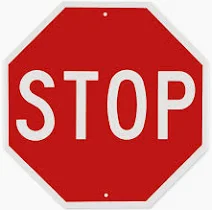

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
frames = []

# above b2, high enough for the held block to clear it
q_pre_place = choose_solution(analytical_ik(*pose_above("b2", 0.1 + 2 * BLOCK_HALF_HEIGHT)), get_configuration())
success, new_frames = move_to(q_pre_place)
frames += new_frames

# lower until the held block (nearly) rests on b2
q_place = choose_solution(analytical_ik(*pose_above("b2", 2 * BLOCK_HALF_HEIGHT + 0.005)), get_configuration())
success, new_frames = move_to(q_place)
frames += new_frames

release()

# retreat
success, new_frames = move_to(q_pre_place)
frames += new_frames

show_video(frames)
print("block positions:", get_block_positions())

We just executed `pick-up(b5, t3)` followed by `stack(b5, b2)` with a (simulated) robot arm. Each step consisted of a target pose in the workspace, inverse kinematics, and a direct move to the resulting configuration. This process is quite straightforward. Nothing should go wrong, right?

# Straight lines in configuration space

`move_to` sends all joints toward their targets at once, so between two configurations the robot moves (roughly) along a **straight line in configuration space**. A straight line in configuration space is *not* a straight line in the workspace. The tool sweeps an arc, and so does every link of the arm. Nothing in our pipeline checks what this arc passes through.

Let's set up a case where this causes a problem. All eight IK solutions for a pose above `b1` are valid, collision-free configurations. We pick one of them that happens to be in a different "family" than our home configuration and simply go there.

In [ ]:
reset()
solutions = analytical_ik(*pose_above("b1", 0.1 + 2 * BLOCK_HALF_HEIGHT))
q_target = solutions[6]
print("target configuration in collision:", in_collision(q_target))

reset()
success, frames = move_to(q_target, camera="overview")
print("reached:", success, " remaining distance to target: %.2f rad" % np.linalg.norm(get_configuration() - q_target))
show_video(frames)

The robot never arrives. On its way it runs into the environment, and the servos keep pushing against it. To see the path it was trying to follow, let's teleport the robot to intermediate configurations on the straight line from `HOME` to the target, and render the first one that is in collision.

In [ ]:
def interpolate(q_from, q_to, n_steps):
    """n_steps configurations evenly spaced on the straight line from q_from to q_to (inclusive)."""
    return [q_from + t * (q_to - q_from) for t in np.linspace(0, 1, n_steps)]


for t, q in zip(np.linspace(0, 1, 60), interpolate(HOME, q_target, 60)):
    if in_collision(q):
        print(f"first collision at {t:.0%} of the way")
        set_configuration(q)
        media.show_image(render("overview"))
        break

⚒ **Task 6**: Implement `path_in_collision`, which checks whether the straight line between two configurations passes through a collision (by checking a number of intermediate configurations). Then use it to find out which of the eight solutions for the pose above `b1` can be reached from `HOME` in a straight line, and verify your answer by executing one that can and one that cannot.

In [ ]:
def path_in_collision(q_from, q_to, n_steps=50):
    """Whether the straight line in configuration space from q_from to q_to passes through a collision."""
    return False  # your code here


print("path from HOME in collision:", [path_in_collision(HOME, q) for q in solutions])

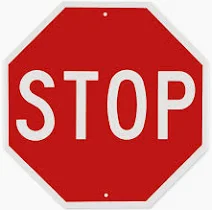

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
def path_in_collision(q_from, q_to, n_steps=50):
    return any(in_collision(q) for q in interpolate(q_from, q_to, n_steps))


print("path from HOME in collision:", [path_in_collision(HOME, q) for q in solutions])

reachable = [q for q in solutions if not path_in_collision(HOME, q)]
reset()
success, frames = move_to(reachable[0], camera="overview")
print("reached:", success)
show_video(frames)

❓ **Is there always a solution that can be reached in a straight line?** Think of a tall tower of blocks standing between the robot and its target, or of the block we are holding (which now moves with the robot and can collide too; our `in_collision` ignores it). And even when a straight line exists, is it a *good* motion?

When no straight line works, the motion has to pass through intermediate configurations, and finding them is the topic of the next tutorial. The two ingredients we built here, a collision check for a single configuration and one for the straight line between two, are what we will need for that.

⚒ **Bonus task**: Straight lines in the *workspace* are often what we want (think of sliding a block along a table). Implement a "Cartesian" motion: interpolate the *pose* of the tool center point between its current pose and a target 20 cm away at the same height, solve IK for each intermediate pose, and execute the resulting configurations one after the other. Watch what happens if, for each intermediate pose, you pick `solutions[0]` instead of the solution closest to the previous configuration.

In [ ]:
# your code here

# What have we done and what comes next?

In this tutorial we met our robot in a physics simulator and saw that its state is a vector of joint angles and object poses rather than a set of facts. We distinguished the workspace, where tasks are naturally specified, from the configuration space, where the robot is controlled. We computed forward kinematics as a chain of transformations, implemented a numerical inverse kinematics solver based on the Jacobian, used an analytical solver that returns all solutions, and used them to ground the pick-up and stack actions of the previous tutorial. Finally, we saw that having a target configuration is not the same as having a safe way to get there.

In the next tutorials, we will:

* find collision-free ways to move between configurations,
* look inside the position servos and see how **control** makes the robot follow those motions,
* turn simulated (and noisy) observations back into facts like `(on b2 b1)` with **state estimation**,
* and finally put it all together with the task planner from the previous tutorial.